# Chapter 19 — End-to-End Data Analysis Capstone

Combine file ingestion, validation, SQL, Pandas, statistics, visualization, machine learning, and communication into a reproducible portfolio project. Use the supplied synthetic sales/customer datasets.

## Prerequisites
Completion of the earlier foundations, processing, database, visualization, and analysis chapters.

## Learning goals
- Design a complete analytical workflow from a business question.
- Load, validate, clean, and join multiple data sources.
- Create reproducible metrics and statistical analyses.
- Build visual findings and a simple predictive baseline.
- Deliver a documented notebook, exported outputs, and dashboard-ready dataset.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Guided learning path

Work from top to bottom. Each step states the purpose, explains the API choice, and provides a complete code cell. Modify parameters and predict the output before running it.

### Step 1 — Load and validate the project datasets

This step builds on the concepts from the chapter. Inspect inputs, argument values, returned objects, and printed/displayed output. Change one parameter at a time to see how behavior changes.

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd
sales=pd.read_csv(DATA/"sales.csv",parse_dates=["order_date"]); customers=pd.read_csv(DATA/"customers.csv",parse_dates=["signup_date"])
print("Sales:",sales.shape,"Customers:",customers.shape)
assert sales.order_id.is_unique; assert customers.customer_id.is_unique
assert sales.customer_id.isin(customers.customer_id).all()
print("Key checks passed")

Data directory: /mnt/data/python_data_analysis_book/data
Sales: (240, 11) Customers: (15, 5)
Key checks passed


### Step 2 — Join customer attributes

This step builds on the concepts from the chapter. Inspect inputs, argument values, returned objects, and printed/displayed output. Change one parameter at a time to see how behavior changes.

In [3]:
analysis=sales.merge(customers,on="customer_id",how="left",validate="many_to_one",indicator=True)
print(analysis._merge.value_counts()); analysis=analysis.drop(columns="_merge"); display(analysis.head())

_merge
both          240
left_only       0
right_only      0
Name: count, dtype: int64
  order_id order_date region  ...    city  signup_date    segment
0    O0101 2025-01-02  North  ...  Mumbai   2024-08-18     Retail
1    O0143 2025-01-03   West  ...   Delhi   2024-06-10     Retail
2    O0120 2025-01-04   West  ...   Delhi   2024-11-18  Corporate
3    O0188 2025-01-05  South  ...   Delhi   2024-06-10     Retail
4    O0047 2025-01-07   East  ...   Delhi   2024-01-24  Corporate

[5 rows x 15 columns]


### Step 3 — Create business metrics

This step builds on the concepts from the chapter. Inspect inputs, argument values, returned objects, and printed/displayed output. Change one parameter at a time to see how behavior changes.

In [4]:
analysis["profit_margin"]=analysis.profit/analysis.revenue
metrics={"orders":analysis.order_id.nunique(),"revenue":analysis.revenue.sum(),"profit":analysis.profit.sum(),"units":analysis.units.sum(),"aov":analysis.revenue.sum()/analysis.order_id.nunique(),"margin":analysis.profit.sum()/analysis.revenue.sum()}
print(metrics); display(analysis.groupby("segment").agg(orders=("order_id","nunique"),revenue=("revenue","sum"),profit=("profit","sum")))

{'orders': 240, 'revenue': np.float64(39419509.66), 'profit': np.float64(9352640.84), 'units': np.int64(2302), 'aov': np.float64(164247.95691666665), 'margin': np.float64(0.2372591876628635)}
           orders      revenue      profit
segment                                   
Corporate      96  12896063.01  2644675.63
Retail         96  17525051.14  4153672.86
SMB            48   8998395.51  2554292.35


### Step 4 — Create a time-series summary

This step builds on the concepts from the chapter. Inspect inputs, argument values, returned objects, and printed/displayed output. Change one parameter at a time to see how behavior changes.

In [5]:
daily=analysis.groupby("order_date").agg(revenue=("revenue","sum"),profit=("profit","sum"),orders=("order_id","nunique")).sort_index(); daily["revenue_7d_avg"]=daily.revenue.rolling(7,min_periods=1).mean(); display(daily.head())

              revenue    profit  orders  revenue_7d_avg
order_date                                             
2025-01-02  219935.79  80562.93       1   219935.790000
2025-01-03   11895.39   4092.40       1   115915.590000
2025-01-04   16659.20   3653.15       1    82830.126667
2025-01-05   15634.04   2575.22       1    66031.105000
2025-01-07    8934.03   1371.98       1    54611.690000


### Step 5 — Visualize and export results

This step builds on the concepts from the chapter. Inspect inputs, argument values, returned objects, and printed/displayed output. Change one parameter at a time to see how behavior changes.

Exported cleaned data and daily metrics


/mnt/data/python_data_analysis_book/Chapter_19_end_to_end_data_analysis_capstone/Chapter_19_Step_by_Step_Tutorial.ipynb:2: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



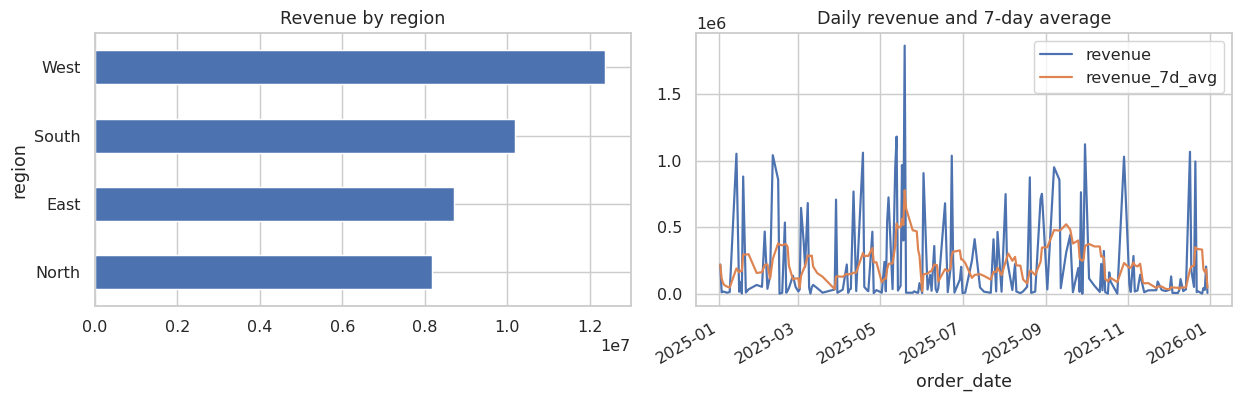

In [6]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(12,4)); analysis.groupby("region").revenue.sum().sort_values().plot(kind="barh",ax=axes[0],title="Revenue by region"); daily[["revenue","revenue_7d_avg"]].plot(ax=axes[1],title="Daily revenue and 7-day average"); plt.tight_layout(); plt.show()
analysis.to_csv("capstone_clean_sales.csv",index=False); daily.to_csv("capstone_daily_metrics.csv"); print("Exported cleaned data and daily metrics")

### Step 6 — Optional SQL aggregation with SQLite

This step builds on the concepts from the chapter. Inspect inputs, argument values, returned objects, and printed/displayed output. Change one parameter at a time to see how behavior changes.

In [7]:
import sqlite3
con=sqlite3.connect(":memory:"); analysis.to_sql("sales_analysis",con,index=False,if_exists="replace")
result=pd.read_sql_query("SELECT region, SUM(revenue) AS revenue, SUM(profit) AS profit FROM sales_analysis GROUP BY region ORDER BY revenue DESC",con); display(result); con.close()

  region      revenue      profit
0   West  12370641.44  3001668.05
1  South  10179983.56  2561412.25
2   East   8707069.76  1811652.55
3  North   8161814.90  1977907.99


## Tutorial checkpoint

1. What was the input data type?
2. What did the function or method return?
3. Which argument most changed the result?
4. What edge case should be tested before using this in production?